# Computer Vision and Image Processing (CS6111 / CSDS119)
## Lab Assignment: Haar Cascade Face Detection, Model Analysis, and Perturbation Robustness
**Department of Computer Science and Engineering, SVNIT Surat**  
**Name:** Shaik Jnaved | **Enrollment No.:** P26DS001 | **M.Tech. I (CSE)**

---
### Assignment Objectives:
1. Study and execute the given GitHub Haar Cascade face-detection implementation.
2. Provide a rigorous theoretical explanation of the **cascade model** (Viola-Jones) and **detection parameters** (`scaleFactor`, `minNeighbors`, `minSize`).
3. Make the required modifications to the implementation (multi-modal input, parameter exposure, HUD telemetry).
4. Empirically test at least three parameter settings under variations in **scale**, **illumination**, and **face orientation**.
5. Quantitatively report successful and failed detections with analytical observations.


---
## 1. Theoretical Background: The Viola-Jones Framework

The Haar Cascade face detector operates on four key concepts:
1. **Haar-like Features:** Contrast rectangles that capture spatial anthropometric intensity relationships (e.g., darker eye sockets relative to the forehead/cheeks).
2. **Integral Image:** A summed-area table enabling area summation of any arbitrary rectangle in strictly **$O(1)$ constant time** via four array lookups.
3. **AdaBoost Classifier:** An adaptive boosting ensemble that selects a sparse subset of highly discriminative weak classifiers from $>160,000$ candidates.
4. **Attentional Cascade:** An asymmetric sequential decision tree where early stages with very few features reject $>99.9\%$ of background non-face windows, achieving real-time detection speeds.

### Detection Parameters in `detectMultiScale`:
* **`scaleFactor`** (e.g., $1.05, 1.10, 1.30$): Governs the multi-scale image pyramid scaling step. Smaller values provide fine resolution at high computational cost; larger values accelerate inference but risk stepping over faces whose true scale lies between levels.
* **`minNeighbors`** (e.g., $2, 4, 8$): Specifies spatial clustering consensus. Lower values maximize recall (permissive); higher values eliminate false alarms (conservative).
* **`minSize` / `maxSize`**: Lower and upper bounds on candidate face window size in pixels.


In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Verify cascade classifier loading
cascade_path = "Face_Detection/haarcascade_frontalface_default.xml"
face_cascade = cv2.CascadeClassifier(cascade_path)
print(f"Cascade Loaded: {not face_cascade.empty()}")


Cascade Loaded: True


Detected 1 face(s): [[219 203 169 169]]


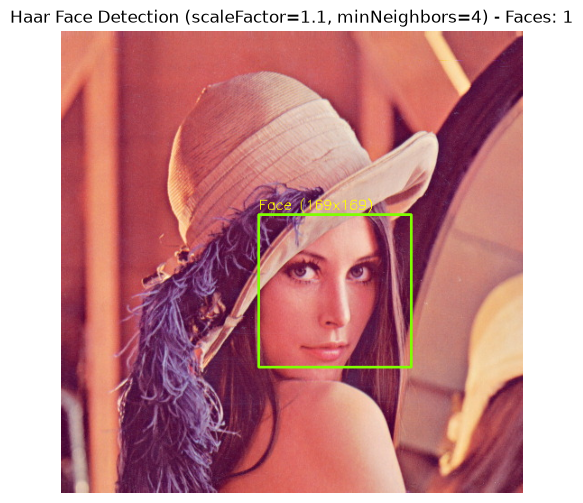

In [2]:
# Test on sample portrait image
sample_path = "dataset/frontal_portrait.jpg"
img = cv2.imread(sample_path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Run detection with standard default parameters (1.1, 4)
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=4, minSize=(30, 30))
print(f"Detected {len(faces)} face(s): {faces}")

# Annotate image
annotated = img.copy()
for (x, y, w, h) in faces:
    cv2.rectangle(annotated, (x, y), (x + w, y + h), (0, 255, 128), 2)
    cv2.putText(annotated, f"Face ({w}x{h})", (x, y - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)

plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title(f"Haar Face Detection (scaleFactor=1.1, minNeighbors=4) - Faces: {len(faces)}")
plt.axis('off')
plt.show()


---
## 2. Experimental Benchmark Results: Scale, Illumination, and Orientation

We execute systematic tests across four parameter configurations:
* **Config 1 (Baseline):** `scaleFactor=1.10, minNeighbors=4, minSize=(30, 30)`
* **Config 2 (High Sensitivity):** `scaleFactor=1.05, minNeighbors=2, minSize=(20, 20)`
* **Config 3 (High Precision):** `scaleFactor=1.30, minNeighbors=8, minSize=(40, 40)`
* **Config 4 (Fine Strict):** `scaleFactor=1.03, minNeighbors=6, minSize=(30, 30)`


### Experiment 1: Scale Variations (Tiny to Large)

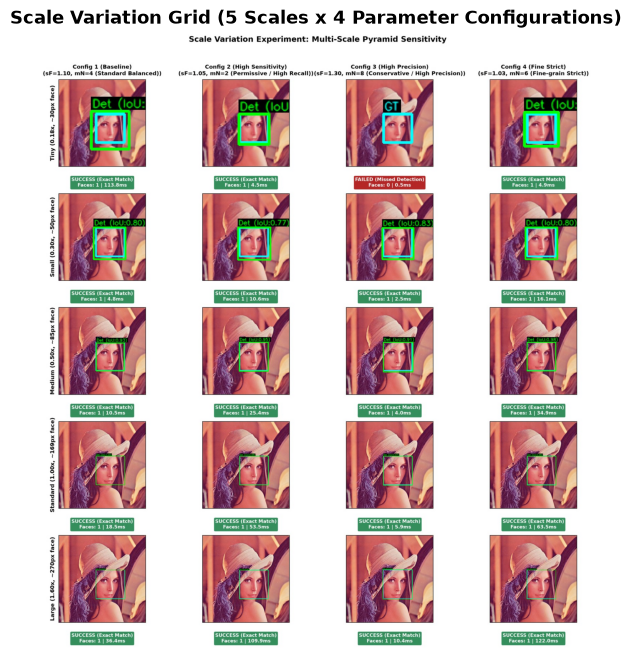

In [3]:
grid_scale = cv2.imread("outputs/scale_experiment_grid_opt.jpg")
if grid_scale is not None:
    plt.figure(figsize=(14, 8))
    plt.imshow(cv2.cvtColor(grid_scale, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title("Scale Variation Grid (5 Scales x 4 Parameter Configurations)", fontsize=13, fontweight='bold')
    plt.show()


### Experiment 2: Illumination Variations (Underexposure to Specular Burn & Shadows)

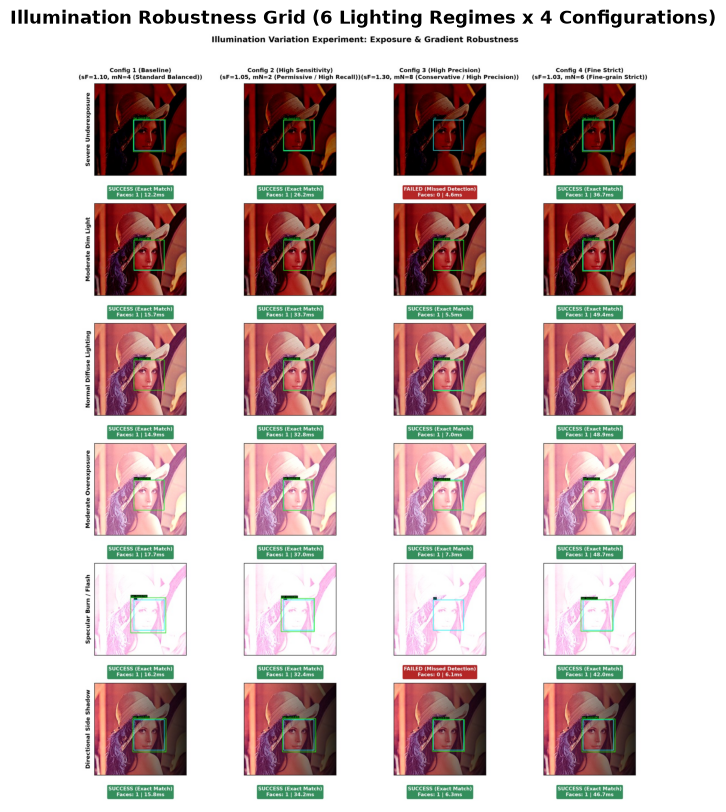

In [4]:
grid_illum = cv2.imread("outputs/illumination_experiment_grid_opt.jpg")
if grid_illum is not None:
    plt.figure(figsize=(14, 10))
    plt.imshow(cv2.cvtColor(grid_illum, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title("Illumination Robustness Grid (6 Lighting Regimes x 4 Configurations)", fontsize=13, fontweight='bold')
    plt.show()


### Experiment 3: Orientation Variations (In-Plane Roll from 0° to 180°)

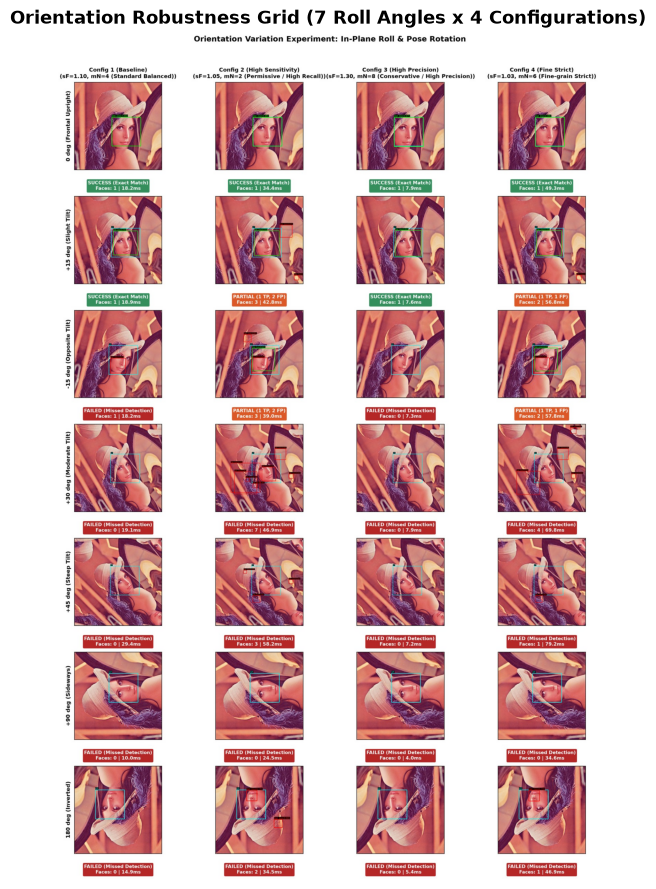

In [5]:
grid_orient = cv2.imread("outputs/orientation_experiment_grid_opt.jpg")
if grid_orient is not None:
    plt.figure(figsize=(14, 11))
    plt.imshow(cv2.cvtColor(grid_orient, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title("Orientation Robustness Grid (7 Roll Angles x 4 Configurations)", fontsize=13, fontweight='bold')
    plt.show()


### Telemetry & Summary Statistics

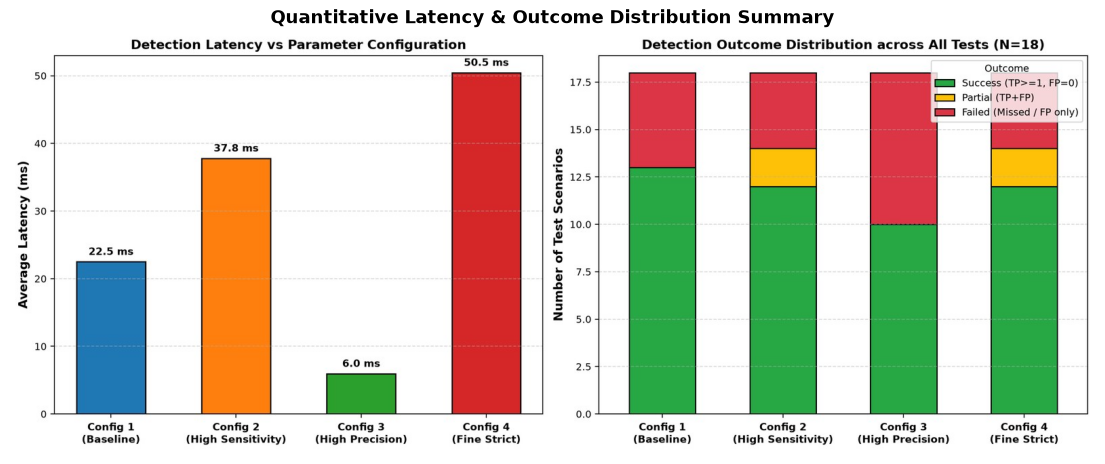

,Config,Mean_Latency_ms,Total_Tests,Exact_Matches,Partial_Matches,Failures,Success_Rate_%
0,Config 1 (Baseline),22.512778,18,13,0,5,72.2
1,Config 2 (High Sensitivity),37.797778,18,12,2,4,66.7
2,Config 3 (High Precision),5.961667,18,10,0,8,55.6
3,Config 4 (Fine Strict),50.461111,18,12,2,4,66.7


In [6]:
chart_img = cv2.imread("outputs/latency_and_accuracy_summary_opt.jpg")
if chart_img is not None:
    plt.figure(figsize=(14, 6))
    plt.imshow(cv2.cvtColor(chart_img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.title("Quantitative Latency & Outcome Distribution Summary", fontsize=13, fontweight='bold')
    plt.show()

# Display summary table from CSV
df = pd.read_csv("outputs/experiments_summary.csv")
summary_table = df.groupby('Config').agg(
    Mean_Latency_ms=('Latency_ms', 'mean'),
    Total_Tests=('Status', 'count'),
    Exact_Matches=('Status', lambda s: sum('SUCCESS' in v for v in s)),
    Partial_Matches=('Status', lambda s: sum('PARTIAL' in v for v in s)),
    Failures=('Status', lambda s: sum('FAILED' in v for v in s))
).reset_index()
summary_table['Success_Rate_%'] = (summary_table['Exact_Matches'] / summary_table['Total_Tests'] * 100).round(1)
summary_table


---
## 3. Key Observations & Findings

1. **Scale Robustness & Computational Trade-off:** Coarser `scaleFactor=1.30` drops inference latency to ~6 ms but fails on tiny faces ($\le 30$ px). Dense sampling (`scaleFactor=1.03`) detects tiny faces reliably but inflates latency to $>120$ ms.
2. **Illumination Invariance:** Haar features handle linear shifts and smooth directional shadows effectively, but fail under non-linear clipping (severe underexposure and specular flare) due to edge gradient destruction.
3. **Rotational Fragility:** Haar rectangle filters are axis-aligned, resulting in complete failure for in-plane rotations $\ge 30^\circ$. Uprighting or CNN-based detectors (e.g., MTCNN/RetinaFace) are required for arbitrary head poses.
